In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import(confusion_matrix, classification_report,precision_score,recall_score,f1_score,roc_auc_score,ConfusionMatrixDisplay,RocCurveDisplay)


In [2]:
df=pd.read_csv("/content/creditcard.csv")


In [3]:
df.shape

(11959, 31)

In [4]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0.0
1,0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0.0
2,1,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0.0
3,1,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0.0
4,2,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0.0


In [5]:
df.tail()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
11954,20631,1.504204,-0.411728,0.200090,-0.778753,-0.442232,-0.119677,-0.782660,-0.165178,0.691819,...,-0.136231,-0.217274,-0.143260,-1.057332,0.529188,-0.235062,-0.012089,0.000905,9.00,0.0
11955,20636,1.134994,0.096340,0.277921,0.319692,0.742800,1.611803,-0.458649,0.390012,1.424541,...,-0.395605,-0.743542,0.222256,-1.859104,-0.109777,0.279049,0.012398,-0.009090,0.99,0.0
11956,20638,-6.305012,3.944886,-4.707362,1.539602,-3.934785,-1.730565,-2.104936,3.843447,0.863458,...,0.073140,-0.039935,-0.108896,0.691434,-0.261979,-0.447540,0.212900,-0.031021,89.99,0.0
11957,20638,1.161960,-0.398297,1.123732,-0.474237,-1.226667,-0.519325,-0.804179,0.070134,3.262926,...,-0.121191,0.097255,0.050903,0.330479,0.315692,-0.712765,0.073836,0.028055,11.85,0.0
11958,20642,1.291096,-0.226628,0.708386,-0.719236,-0.659099,-0.273757,-0.612042,-0.111488,3.032258,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11959 entries, 0 to 11958
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Time    11959 non-null  int64  
 1   V1      11959 non-null  float64
 2   V2      11959 non-null  float64
 3   V3      11959 non-null  float64
 4   V4      11959 non-null  float64
 5   V5      11959 non-null  float64
 6   V6      11959 non-null  float64
 7   V7      11959 non-null  float64
 8   V8      11959 non-null  float64
 9   V9      11959 non-null  float64
 10  V10     11959 non-null  float64
 11  V11     11959 non-null  float64
 12  V12     11959 non-null  float64
 13  V13     11959 non-null  float64
 14  V14     11959 non-null  float64
 15  V15     11959 non-null  float64
 16  V16     11959 non-null  float64
 17  V17     11959 non-null  float64
 18  V18     11959 non-null  float64
 19  V19     11959 non-null  float64
 20  V20     11958 non-null  float64
 21  V21     11958 non-null  float64
 22

In [7]:
df.isnull().sum().sum()

np.int64(11)

In [8]:
print("Categories:",df["Class"].unique())

Categories: [ 0.  1. nan]


In [9]:
print("\nCategory counts:")
print(df["Class"].value_counts())


Category counts:
Class
0.0    11906
1.0       52
Name: count, dtype: int64


In [10]:
print(df["Class"].value_counts(normalize=True)*100)

Class
0.0    99.565145
1.0     0.434855
Name: proportion, dtype: float64


In [11]:
x=df.drop("Class",axis=1)
y=df["Class"]
print("Features shape:",x.shape)
print("Target shape:",y.shape)
print("\nFeatures:")
print(x.columns.tolist())

Features shape: (11959, 30)
Target shape: (11959,)

Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [12]:
print(y.isnull().sum())

1


In [13]:
print(df.columns)

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')


In [14]:

df = df.dropna(subset=['Class'])


x = df.drop('Class', axis=1)
y = df['Class']


x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=42, stratify=y
)

print("Training data:", x_train.shape, y_train.shape)
print("Testing data:", x_test.shape, y_test.shape)

Training data: (9566, 30) (9566,)
Testing data: (2392, 30) (2392,)


In [15]:
model=RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)
model.fit(x_train,y_train);

In [16]:
y_pred=model.predict(x_test)
y_prob=model.predict_proba(x_test)[:,1]
print("Actual labels:")
print(y_test.head(20))
print("Predicted labels:")
print(y_pred[:20])


Actual labels:
7855     0.0
94       0.0
1526     0.0
5393     0.0
4808     0.0
6172     0.0
7291     0.0
4750     0.0
3718     0.0
2575     0.0
7739     0.0
4614     0.0
8812     0.0
7200     0.0
9692     0.0
9304     0.0
3777     0.0
9041     0.0
10035    0.0
11085    0.0
Name: Class, dtype: float64
Predicted labels:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


Confusion Matrix:
[[2382    0]
 [   3    7]]


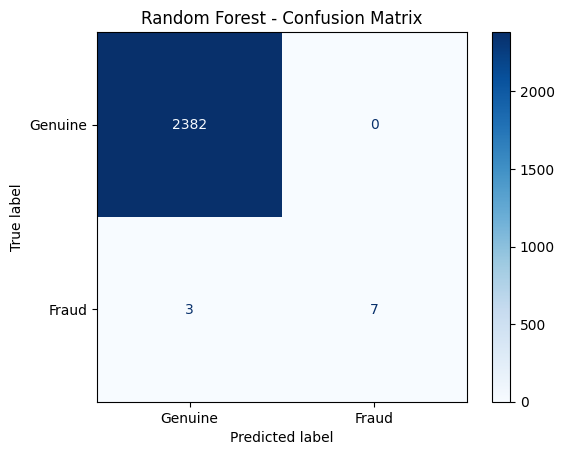

In [17]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Genuine", "Fraud"]
).plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.show()

In [19]:
precision = precision_score(
    y_test, y_pred, zero_division=0
)

recall = recall_score(
    y_test, y_pred, zero_division=0
)

f1 = f1_score(
    y_test, y_pred, zero_division=0
)

roc_auc = roc_auc_score(y_test, y_prob)

print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")
print(f"ROC-AUC   : {roc_auc:.4f}")

print("\nDetailed Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)

MODEL EVALUATION RESULTS
------------------------
Precision : 1.0000
Recall    : 0.7000
F1-score  : 0.8235
ROC-AUC   : 0.9482

Detailed Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00      2382
       Fraud       1.00      0.70      0.82        10

    accuracy                           1.00      2392
   macro avg       1.00      0.85      0.91      2392
weighted avg       1.00      1.00      1.00      2392



In [21]:
# Combine test data and predictions
results = x_test.copy()
results["Actual"] = y_test
results["Predicted"] = y_pred
results["Fraud_Probability"] = y_prob

# Select actual fraud transactions
actual_fraud = results[results["Actual"] == 1]

print("Total actual fraud cases:", len(actual_fraud))
print(actual_fraud[["Time", "Amount", "Actual", "Predicted", "Fraud_Probability"]].head(20))

# Count detected and missed fraud cases
print("Fraud detected:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 1)]))
print("Fraud missed:", len(results[(results["Actual"] == 1) & (results["Predicted"] == 0)]))

# Save fraud transactions
actual_fraud.to_csv("actual_fraudulent_test_transactions.csv", index=True)
print("File saved successfully!")

Total actual fraud cases: 10
        Time  Amount  Actual  Predicted  Fraud_Probability
6329    7519    1.00     1.0        0.0               0.14
10891  18675  188.78     1.0        1.0               0.76
9252   13323    1.00     1.0        1.0               0.97
4920    4462  239.93     1.0        0.0               0.11
623      472  529.00     1.0        0.0               0.00
11880  20451    1.00     1.0        1.0               0.95
10630  17838  766.36     1.0        1.0               0.75
6774    8528    1.00     1.0        1.0               0.99
9487   14073    1.00     1.0        1.0               0.98
11710  20011    1.00     1.0        1.0               0.98
Fraud detected: 7
Fraud missed: 3
File saved successfully!


Top 10 Important Features:
V14    0.166373
V3     0.134323
V11    0.103326
V12    0.099605
V2     0.083322
V4     0.081204
V17    0.066795
V10    0.055023
V6     0.036898
V16    0.029480
dtype: float64


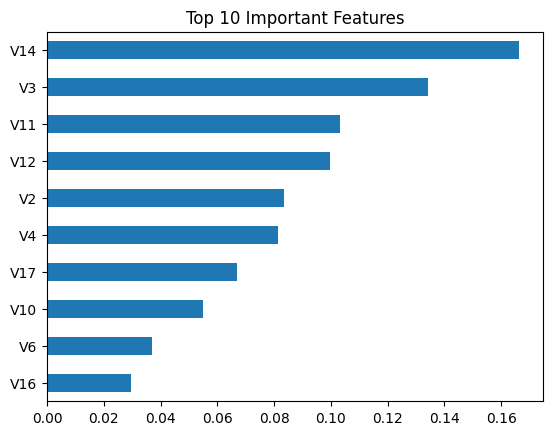

In [23]:

# Get feature importance
importance = pd.Series(model.feature_importances_, index=x.columns)

# Display top 10 important features
top10 = importance.nlargest(10)
print("Top 10 Important Features:")
print(top10)

# Plot the features
top10.sort_values().plot(kind="barh")
plt.title("Top 10 Important Features")
plt.show()

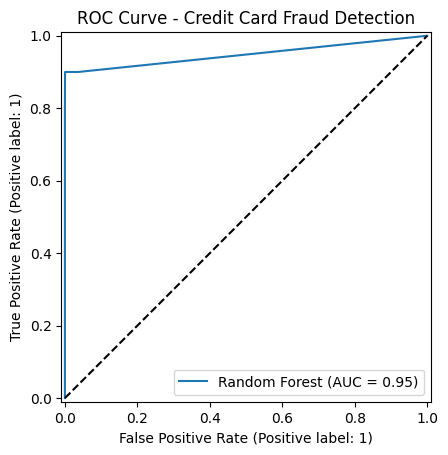

In [24]:

RocCurveDisplay.from_predictions(
    y_test,
    y_prob,
    name="Random Forest"
)

plt.title("ROC Curve - Credit Card Fraud Detection")
plt.plot([0, 1], [0, 1], "k--")
plt.show()